
# Project: Investigate a Dataset 

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>


<a id='intro'></a>
## Introduction

### Dataset Description 

The dataset includes information from 100k medical appointments in Brazil. Each row includes a number of different characteristics.

- **PatientId** - Unique identifier for each patient
- **AppointmentID** - Unique identifier for each appointment
- **Gender** - Patient's gender (M or F)
- **ScheduledDay** - The day the patient set up their appointment
- **AppointmentDay** - The day of the actual appointment
- **Age** - Patient's age
- **Neighbourhood** - The location of the hospital
- **Scholarship** - Whether the patient is enrolled in the Brazilian welfare 
program Bolsa Família (0 = No, 1 = Yes)
- **Hipertension** - Whether the patient has hypertension (0 = No, 1 = Yes)
- **Diabetes** - Whether the patient has diabetes (0 = No, 1 = Yes)
- **Alcoholism** - Whether the patient has alcoholism (0 = No, 1 = Yes)
- **Handcap** - Whether the patient has a handicap (0 = No, 1 = Yes)
- **SMS_received** - Whether the patient received an SMS reminder (0 = No, 1 = Yes)
- **No-show** - Whether the patient missed their appointment. Note: 'Yes' means 
the patient **did not** show up, and 'No' means they **did** show up.

### Question(s) for Analysis
- Is a patient's no-show status correlated to welfare enrollment?
- Does age have a positive or negative correlation with no-show status?
- Does neighborhood location show differences in no-show rates?


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

<a id='wrangling'></a>
## Data Wrangling

### General Properties


In [2]:
df = pd.read_csv('Database_No_show_appointments/noshowappointments-kagglev2-may-2016.csv')

df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [3]:
# Checking the shape and first few rows. Noticed that the Patientid is using exponents. 'Scholarship' to 'SMS_received' do not use Yes/No.
df.shape

(110527, 14)

In [4]:
# PatientId is using float and not integer. 'ScheduledDay' and 'AppointmentDay' are objects. 'Hipertension' and 'Handcap' contain typos.
df.dtypes

PatientId         float64
AppointmentID       int64
Gender             object
ScheduledDay       object
AppointmentDay     object
Age                 int64
Neighbourhood      object
Scholarship         int64
Hipertension        int64
Diabetes            int64
Alcoholism          int64
Handcap             int64
SMS_received        int64
No-show            object
dtype: object

In [5]:
# 'Age' minimum is -1. "No-show" doesn't appear as it is stored as an object.
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [6]:
# No missing values.
df.isnull().sum()

PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64


### Data Cleaning



### Assessment
### After inspecting the dataset, I found these issues:
'Hipertension' and 'Handcap' contain typos.
'Age' has a minimum of -1.
'ScheduledDay' and 'AppointmentDay' are stored as strings.
'No-show' should be changed to numeric with special attention to the strange 'Yes/No'


In [7]:
# Renaming colummns
df= df.rename(columns={
    'Hipertension': 'Hypertension',
    'Handcap': 'Handicap'
})
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [8]:
# Dropping minimum values in 'Age' and checking row length to check that it worked.
print(len(df))
invalid_age = df[df['Age'] == -1].index
df.drop(invalid_age, inplace=True)

print(len(df))

110527
110526


In [9]:
# Convert strings to datetime
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])
df.dtypes

PatientId                     float64
AppointmentID                   int64
Gender                         object
ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
Age                             int64
Neighbourhood                  object
Scholarship                     int64
Hypertension                    int64
Diabetes                        int64
Alcoholism                      int64
Handicap                        int64
SMS_received                    int64
No-show                        object
dtype: object

In [10]:
# Change 'No-show' to int dtype
df['No-show_binary'] = (df['No-show'] == 'Yes').astype(int)
print(df['No-show_binary'].value_counts())


0    88207
1    22319
Name: No-show_binary, dtype: int64


<a id='eda'></a>
## Exploratory Data Analysis

### Research Question 1 Is a patient's no show status correlated to welfare enrollment?

A bar chart was chosen for this visualization because we are comparing a single 
numeric value (no-show rate) across two distinct categories (enrolled vs not enrolled 
in scholarship). Bar charts are ideal for comparing values across categorical groups 
making it easy to see differences at a glance.


In [11]:
# Checking scholarship status and no show statue seperately.
df['Scholarship'].value_counts()


0    99665
1    10861
Name: Scholarship, dtype: int64

Text(0, 0.5, 'Number of Patients')

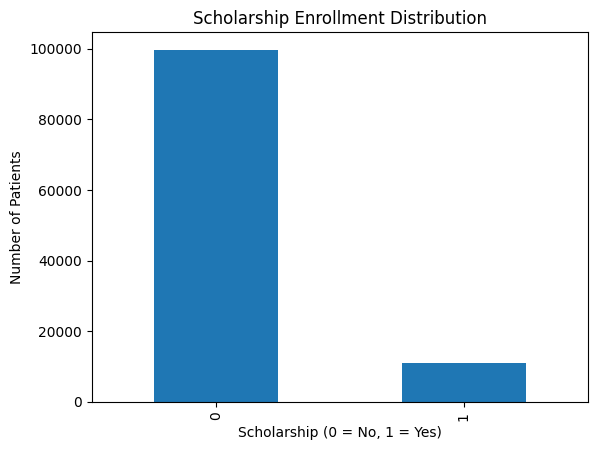

In [12]:
# Visualization for scholarship
df['Scholarship'].value_counts().plot(kind='bar')
plt.title('Scholarship Enrollment Distribution')
plt.xlabel('Scholarship (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')

In [13]:
df['No-show'].value_counts()

No     88207
Yes    22319
Name: No-show, dtype: int64

Text(0, 0.5, 'Number of Patients')

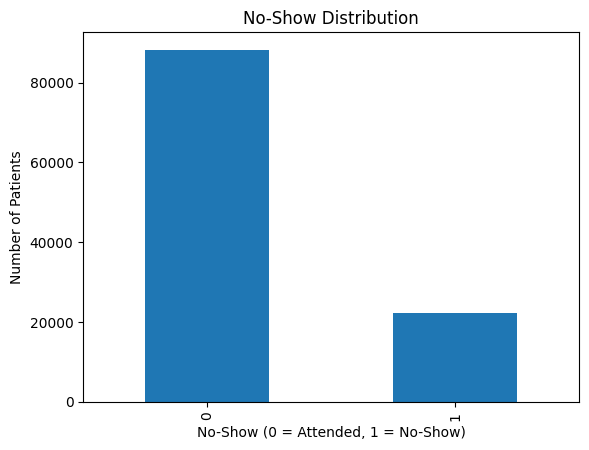

In [14]:
# Visualization for no-show
df['No-show_binary'].value_counts().plot(kind='bar')
plt.title('No-Show Distribution')
plt.xlabel('No-Show (0 = Attended, 1 = No-Show)')
plt.ylabel('Number of Patients')

In [15]:
# 0=not enrolled, 1=enrolled. 
# Patients enrolled in the welfare scholarship had a slightly higher no-show rate.
df.groupby('Scholarship')['No-show_binary'].mean()

Scholarship
0    0.198074
1    0.237363
Name: No-show_binary, dtype: float64

In [16]:
# Reusable function for consistent plot labeling
def format_plot(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)

Text(0, 0.5, 'No-Show Rate (%)')

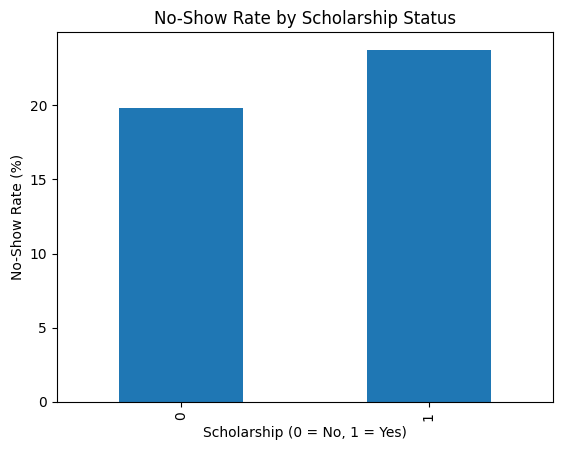

In [17]:
#Visualization for Question 1
no_show_rate = df.groupby('Scholarship')['No-show_binary'].mean() * 100
no_show_rate.plot(kind='bar')
plt.title('No-Show Rate by Scholarship Status')
plt.xlabel('Scholarship (0 = No, 1 = Yes)')
plt.ylabel('No-Show Rate (%)')


### Insights:
The analysis shows that patients enrolled in the Bolsa Família welfare scholarship 
had a no-show rate of approximately 23.7% compared to 19.8% for non-enrolled patients. 
This suggests that scholarship enrollment has a slight positive correlation with 
no-show status. However the difference is small and other factors such as 
transportation access or work schedules may also contribute to missed appointments.


### Research Question 2  Does age have a positive or negative correlation with no-show status?
A histogram was first used to understand the overall age distribution of patients 
before examining no-show rates. A line chart was then chosen to show the no-show 
rate across every age value because it effectively displays trends and patterns 
over a continuous variable like age, making it easy to see whether no-show rates 
increase or decrease as age changes.


In [18]:
# Summary and distribution of ages on a histogram
df['Age'].describe()


count    110526.000000
mean         37.089219
std          23.110026
min           0.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64

Text(0, 0.5, 'Number of Patients')

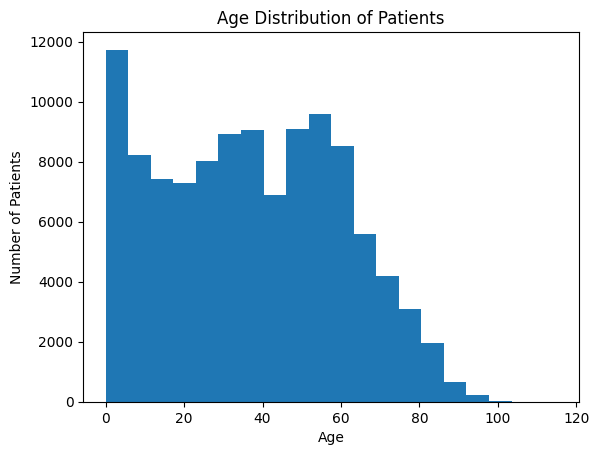

In [19]:
df['Age'].plot(kind='hist', bins=20)
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of Patients')

Text(0, 0.5, 'No-show Rate')

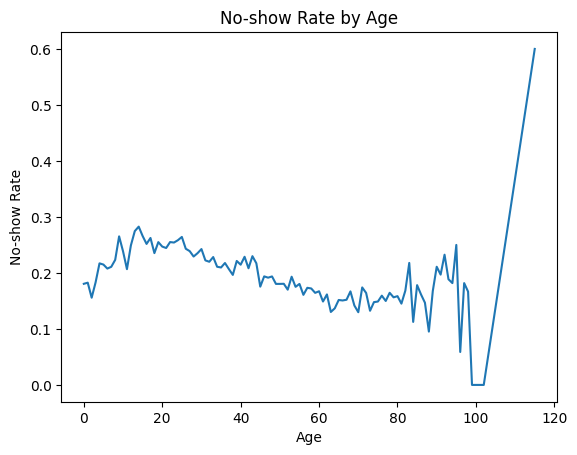

In [20]:
# Visualization for average no-show rate by age.
df.groupby('Age')['No-show_binary'].mean().plot(kind='line')
plt.title('No-show Rate by Age')
plt.xlabel('Age')
plt.ylabel('No-show Rate')

### Insights:
The analysis shows a negative correlation between age and no-show status. Younger 
patients, particularly those under 30, tend to have higher no-show rates compared 
to older patients. No-show rates generally decrease as age increases, suggesting 
that older patients are more likely to attend their appointments. This could be 
because older patients tend to have more serious health conditions that make 
attending appointments a higher priority.


<a id='conclusions'></a>
## Conclusions

### Research Question 1: Is a patient's no show status correlated to welfare enrollment?
Patients enrolled in the welfare scholarship program showed a slightly higher no-show 
rate (24%) compared to non-enrolled patients (20%). Since no statistical test was performed, we cannot say this difference is 
meaningful.

### Research Question 2: Does age have a positive or negative correlation with no-show status?
The data has a weak negative correlation between age and no-show rate. Younger patients (under 30) miss appointments more frequently. No-show rates decline as age increases. Since no statistical test was performed, we cannot say this difference is meaningful.

### Limitations
The spike in no-show rate for patients 95-115 is  unreliable due to very few patients in that age group. 
No statistical tests were performed.
Correlation is not causation. Neither welfare scholarship enrollment nor age are proven to cause no-shows based on this analysis alone.

## Further Research
This analysis examined the relationship between no-show status and scholarship 
enrollment, age, and neighborhood location. However there are several areas 
where further research could build upon these findings:

**1. Additional Research Question:**
A natural next step would be to investigate whether the combination of multiple 
factors — such as being young, enrolled in welfare, and living in a specific 
neighborhood — creates an even stronger predictor of no-show status. A more 
advanced analysis could build a predictive model to identify which patients are 
most at risk of missing their appointments, allowing hospitals to target reminder 
interventions more effectively.
